In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import urllib.request
import os


In [2]:

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(url, "sms_spam_collection.zip")

with zipfile.ZipFile("sms_spam_collection.zip", "r") as zip_ref:
    zip_ref.extractall("spam_dataset")

print("Dataset downloaded successfully!")


Dataset downloaded successfully!


In [3]:

df = pd.read_csv(
    "spam_dataset/SMSSpamCollection",
    sep='\t',
    header=None,
    names=['label', 'message']
)

df.head()


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:

print("Dataset Shape:", df.shape)


Dataset Shape: (5572, 2)


In [5]:

print(df.columns)


Index(['label', 'message'], dtype='object')


In [6]:

df.head(10)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [7]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [8]:

print(df['label'].value_counts())


label
ham     4825
spam     747
Name: count, dtype: int64


In [9]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [10]:

print(df.isnull().sum())


label      0
message    0
dtype: int64


In [11]:

print("Duplicate Rows:", df.duplicated().sum())


Duplicate Rows: 403


In [12]:

df = df.drop_duplicates()

print("Dataset Shape:", df.shape)


Dataset Shape: (5169, 2)


In [13]:

import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [14]:

df['clean_message'] = df['message'].str.lower()

df[['message', 'clean_message']].head()


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro..."


In [15]:

df['clean_message'] = df['clean_message'].apply(
    lambda x: x.translate(str.maketrans('', '', string.punctuation))
)

df[['message', 'clean_message']].head()


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [16]:

df['clean_message'] = df['clean_message'].apply(
    lambda x: re.sub(r'\d+', '', x)
)

df[['message', 'clean_message']].head()


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [17]:

stop_words = set(stopwords.words('english'))

df['clean_message'] = df['clean_message'].apply(
    lambda x: ' '.join(
        word for word in x.split()
        if word not in stop_words
    )
)

df[['message', 'clean_message']].head()


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though


In [18]:

df['tokens'] = df['clean_message'].apply(word_tokenize)

df[['clean_message', 'tokens']].head()


,clean_message,tokens
0,go jurong point crazy available bugis n great ...,"[go, jurong, point, crazy, available, bugis, n..."
1,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,free entry wkly comp win fa cup final tkts st ...,"[free, entry, wkly, comp, win, fa, cup, final,..."
3,u dun say early hor u c already say,"[u, dun, say, early, hor, u, c, already, say]"
4,nah dont think goes usf lives around though,"[nah, dont, think, goes, usf, lives, around, t..."


In [19]:

for i in range(5):
    print("Original:", df['message'].iloc[i])
    print("Cleaned:", df['clean_message'].iloc[i])
    print()


Original: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Cleaned: go jurong point crazy available bugis n great world la e buffet cine got amore wat

Original: Ok lar... Joking wif u oni...
Cleaned: ok lar joking wif u oni

Original: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Cleaned: free entry wkly comp win fa cup final tkts st may text fa receive entry questionstd txt ratetcs apply overs

Original: U dun say so early hor... U c already then say...
Cleaned: u dun say early hor u c already say

Original: Nah I don't think he goes to usf, he lives around here though
Cleaned: nah dont think goes usf lives around though



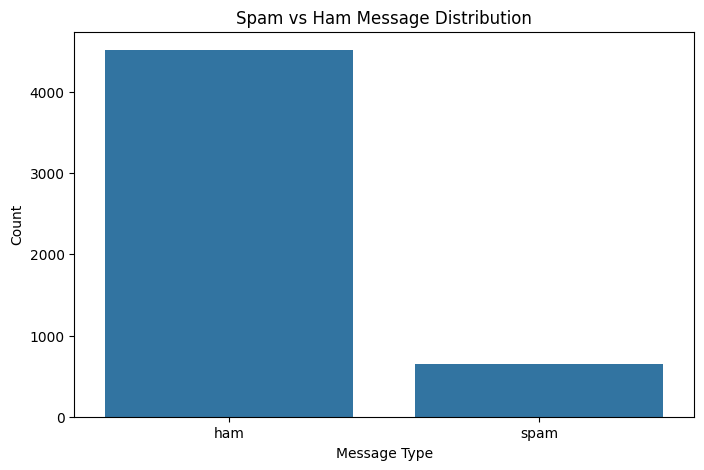

In [20]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='label')

plt.title('Spam vs Ham Message Distribution')
plt.xlabel('Message Type')
plt.ylabel('Count')

plt.show()


In [27]:

df['message_length'] = df['message'].astype(str).apply(len)

print(df.columns)
print(df[['message', 'message_length']].head())


Index(['label', 'message', 'clean_message', 'tokens', 'message_length'], dtype='object')
                                             message  message_length
0  Go until jurong point, crazy.. Available only ...             111
1                      Ok lar... Joking wif u oni...              29
2  Free entry in 2 a wkly comp to win FA Cup fina...             155
3  U dun say so early hor... U c already then say...              49
4  Nah I don't think he goes to usf, he lives aro...              61


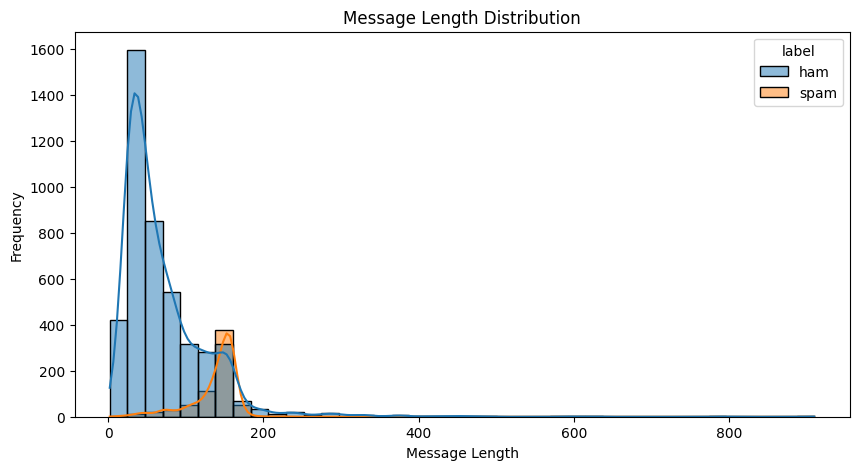

In [28]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='message_length',
    hue='label',
    bins=40,
    kde=True
)

plt.title('Message Length Distribution')
plt.xlabel('Message Length')
plt.ylabel('Frequency')

plt.show()


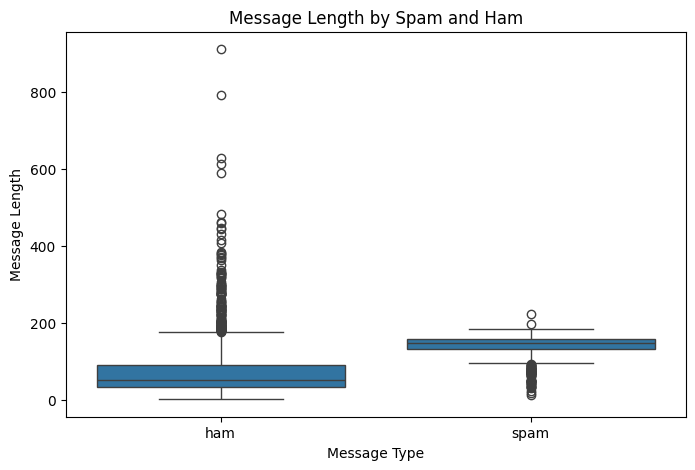

In [29]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='label',
    y='message_length'
)

plt.title('Message Length by Spam and Ham')
plt.xlabel('Message Type')
plt.ylabel('Message Length')

plt.show()


In [30]:

from collections import Counter

all_words = ' '.join(df['clean_message']).split()

word_counts = Counter(all_words)

common_words = word_counts.most_common(15)

print(common_words)


[('u', 1033), ('call', 491), ('im', 451), ('get', 366), ('ur', 321), ('go', 275), ('dont', 264), ('ltgt', 254), ('ok', 252), ('free', 245), ('know', 239), ('got', 233), ('like', 233), ('£', 225), ('good', 219)]


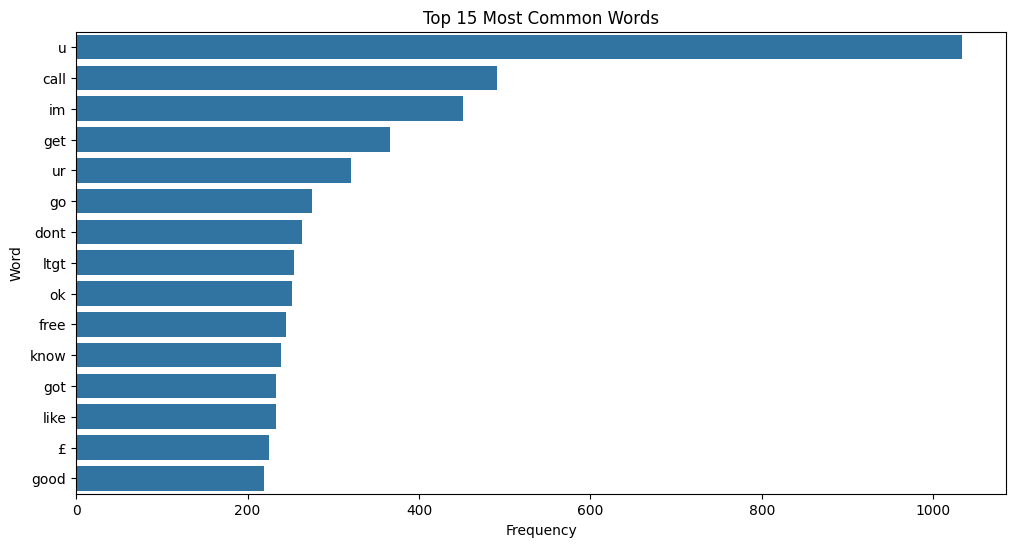

In [31]:

words_df = pd.DataFrame(
    common_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=words_df,
    x='Frequency',
    y='Word'
)

plt.title('Top 15 Most Common Words')
plt.show()


In [32]:

spam_words = ' '.join(
    df[df['label'] == 'spam']['clean_message']
).split()

spam_word_counts = Counter(spam_words)

spam_common_words = spam_word_counts.most_common(15)

print(spam_common_words)


[('call', 305), ('£', 221), ('free', 190), ('u', 130), ('txt', 126), ('ur', 119), ('stop', 108), ('mobile', 106), ('text', 104), ('claim', 96), ('reply', 93), ('prize', 81), ('get', 69), ('new', 64), ('p', 63)]


In [33]:

ham_words = ' '.join(
    df[df['label'] == 'ham']['clean_message']
).split()

ham_word_counts = Counter(ham_words)

ham_common_words = ham_word_counts.most_common(15)

print(ham_common_words)


[('u', 903), ('im', 438), ('get', 297), ('ltgt', 254), ('dont', 248), ('ok', 247), ('go', 244), ('got', 227), ('like', 221), ('know', 221), ('come', 211), ('ill', 207), ('good', 207), ('ur', 202), ('call', 186)]


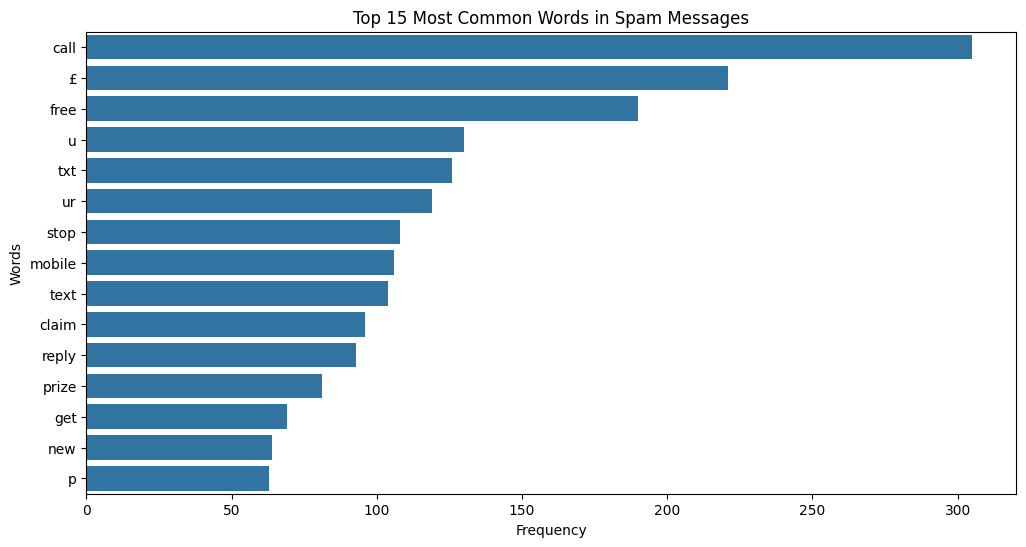

In [34]:

spam_words_df = pd.DataFrame(
    spam_common_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=spam_words_df,
    x='Frequency',
    y='Word'
)

plt.title('Top 15 Most Common Words in Spam Messages')
plt.xlabel('Frequency')
plt.ylabel('Words')

plt.show()


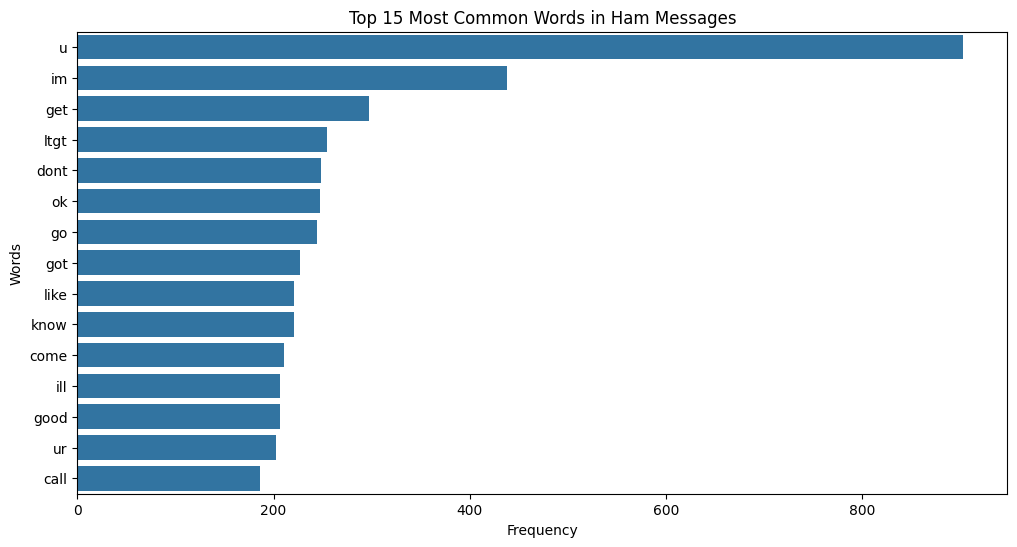

In [35]:

ham_words_df = pd.DataFrame(
    ham_common_words,
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=ham_words_df,
    x='Frequency',
    y='Word'
)

plt.title('Top 15 Most Common Words in Ham Messages')
plt.xlabel('Frequency')
plt.ylabel('Words')

plt.show()


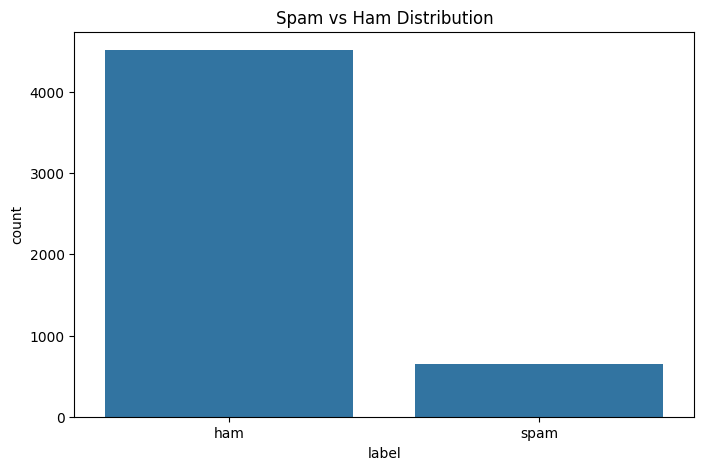

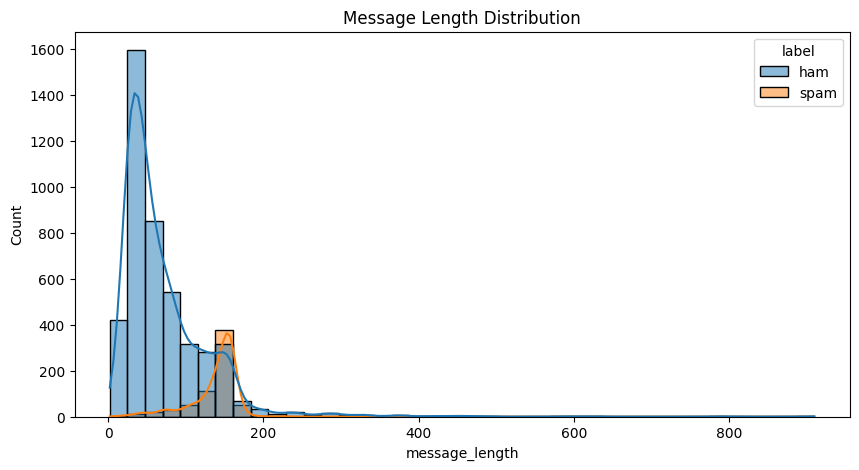

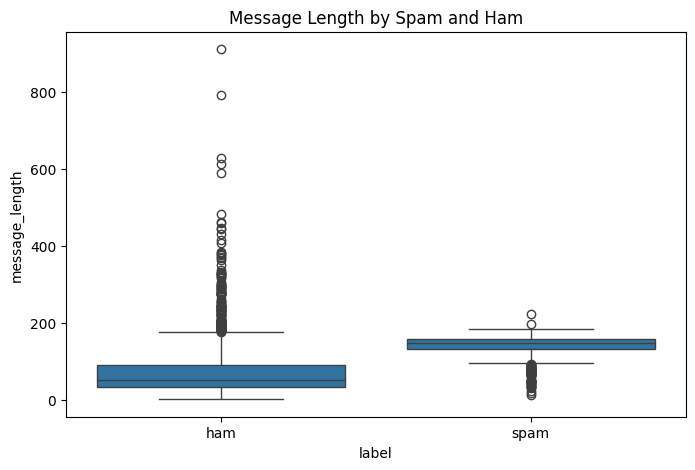

In [36]:

os.makedirs('outputs', exist_ok=True)

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label')
plt.title('Spam vs Ham Distribution')
plt.savefig('outputs/spam_ham_distribution.png')
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='message_length', hue='label', bins=40, kde=True)
plt.title('Message Length Distribution')
plt.savefig('outputs/message_length_distribution.png')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='label', y='message_length')
plt.title('Message Length by Spam and Ham')
plt.savefig('outputs/message_length_boxplot.png')
plt.show()


In [37]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split


In [38]:

X = df['clean_message']
y = df['label']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
0    go jurong point crazy available bugis n great ...
1                              ok lar joking wif u oni
2    free entry wkly comp win fa cup final tkts st ...
3                  u dun say early hor u c already say
4          nah dont think goes usf lives around though
Name: clean_message, dtype: object

Target:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: object


In [39]:

y = y.map({
    'ham': 0,
    'spam': 1
})

print(y.head())


0    0
1    0
2    1
3    0
4    0
Name: label, dtype: int64


In [40]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 4135
Testing samples: 1034


In [41]:

count_vectorizer = CountVectorizer()

X_train_count = count_vectorizer.fit_transform(X_train)

X_test_count = count_vectorizer.transform(X_test)

print("Training Shape:", X_train_count.shape)
print("Testing Shape:", X_test_count.shape)


Training Shape: (4135, 7447)
Testing Shape: (1034, 7447)


In [42]:

tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)


Training Shape: (4135, 7447)
Testing Shape: (1034, 7447)


In [43]:

print("CountVectorizer:")
print("Training:", X_train_count.shape)
print("Testing:", X_test_count.shape)

print("\nTF-IDF:")
print("Training:", X_train_tfidf.shape)
print("Testing:", X_test_tfidf.shape)


CountVectorizer:
Training: (4135, 7447)
Testing: (1034, 7447)

TF-IDF:
Training: (4135, 7447)
Testing: (1034, 7447)


In [44]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


In [45]:

nb_model = MultinomialNB()

nb_model.fit(X_train_count, y_train)

print("Naive Bayes Model Training Completed!")


Naive Bayes Model Training Completed!


In [46]:

nb_predictions = nb_model.predict(X_test_count)

print(nb_predictions[:10])


[0 0 0 0 0 0 0 0 0 0]


In [47]:

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression Model Training Completed!")


Logistic Regression Model Training Completed!


In [48]:

lr_predictions = lr_model.predict(X_test_tfidf)

print(lr_predictions[:10])


[0 0 0 0 0 0 0 0 0 0]


In [49]:

nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Naive Bayes Accuracy:", nb_accuracy)
print("Naive Bayes Accuracy (%):", nb_accuracy * 100)


Naive Bayes Accuracy: 0.9748549323017408
Naive Bayes Accuracy (%): 97.48549323017409


In [50]:

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:", lr_accuracy)
print("Logistic Regression Accuracy (%):", lr_accuracy * 100)


Logistic Regression Accuracy: 0.9516441005802708
Logistic Regression Accuracy (%): 95.16441005802709


In [51]:

model_comparison = pd.DataFrame({
    'Model': ['Naive Bayes', 'Logistic Regression'],
    'Accuracy': [nb_accuracy, lr_accuracy]
})

print(model_comparison)


                 Model  Accuracy
0          Naive Bayes  0.974855
1  Logistic Regression  0.951644


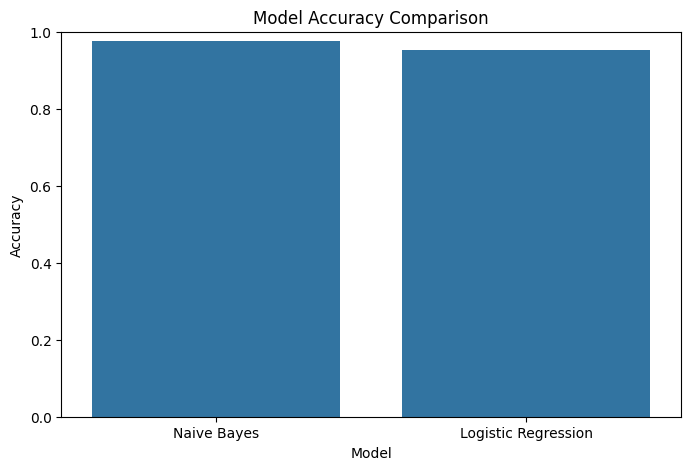

In [52]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Accuracy'
)

plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

plt.show()


In [53]:

print("Naive Bayes Classification Report")

print(
    classification_report(
        y_test,
        nb_predictions,
        target_names=['Ham', 'Spam']
    )
)


Naive Bayes Classification Report
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       903
        Spam       0.92      0.88      0.90       131

    accuracy                           0.97      1034
   macro avg       0.95      0.93      0.94      1034
weighted avg       0.97      0.97      0.97      1034



In [54]:

print("Logistic Regression Classification Report")

print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=['Ham', 'Spam']
    )
)


Logistic Regression Classification Report
              precision    recall  f1-score   support

         Ham       0.95      0.99      0.97       903
        Spam       0.95      0.66      0.77       131

    accuracy                           0.95      1034
   macro avg       0.95      0.83      0.87      1034
weighted avg       0.95      0.95      0.95      1034



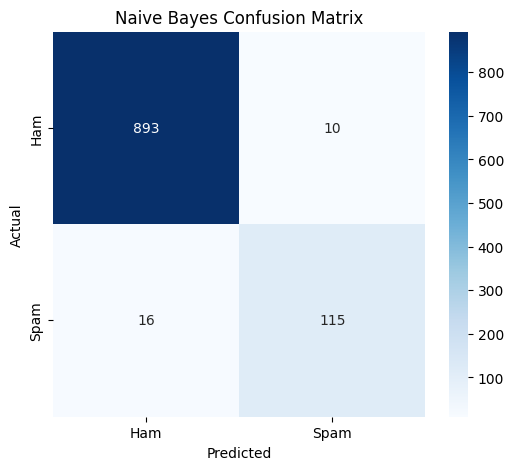

In [55]:

nb_cm = confusion_matrix(y_test, nb_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    nb_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title('Naive Bayes Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()


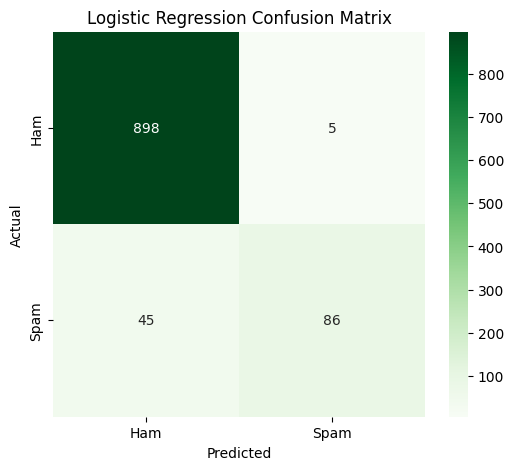

In [56]:

lr_cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()


In [57]:

from sklearn.metrics import precision_score, recall_score, f1_score

evaluation_results = pd.DataFrame({
    'Model': ['Naive Bayes', 'Logistic Regression'],
    'Precision': [
        precision_score(y_test, nb_predictions),
        precision_score(y_test, lr_predictions)
    ],
    'Recall': [
        recall_score(y_test, nb_predictions),
        recall_score(y_test, lr_predictions)
    ],
    'F1-Score': [
        f1_score(y_test, nb_predictions),
        f1_score(y_test, lr_predictions)
    ]
})

print(evaluation_results)


                 Model  Precision    Recall  F1-Score
0          Naive Bayes   0.920000  0.877863  0.898438
1  Logistic Regression   0.945055  0.656489  0.774775


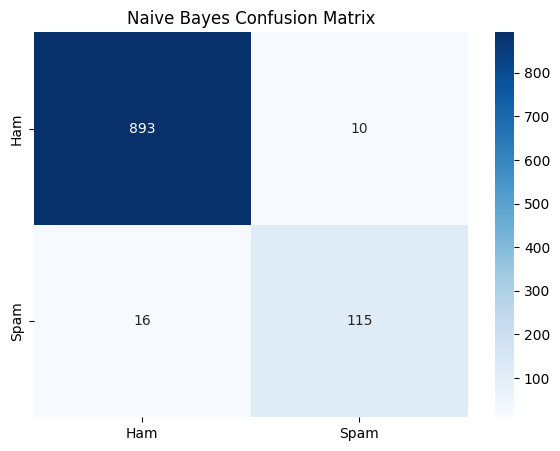

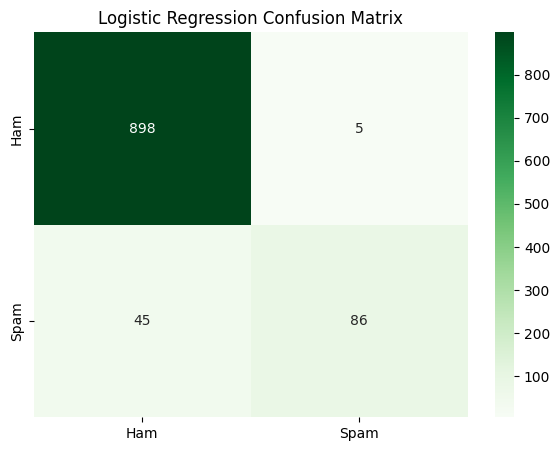

In [58]:

plt.figure(figsize=(7, 5))

sns.heatmap(nb_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'],
            yticklabels=['Ham', 'Spam'])

plt.title('Naive Bayes Confusion Matrix')
plt.savefig('outputs/naive_bayes_confusion_matrix.png',
            bbox_inches='tight')
plt.show()


plt.figure(figsize=(7, 5))

sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Ham', 'Spam'],
            yticklabels=['Ham', 'Spam'])

plt.title('Logistic Regression Confusion Matrix')
plt.savefig('outputs/logistic_regression_confusion_matrix.png',
            bbox_inches='tight')
plt.show()


In [59]:

print(evaluation_results)


                 Model  Precision    Recall  F1-Score
0          Naive Bayes   0.920000  0.877863  0.898438
1  Logistic Regression   0.945055  0.656489  0.774775


In [60]:

best_model_name = evaluation_results.loc[
    evaluation_results['F1-Score'].idxmax(),
    'Model'
]

print("Best Model:", best_model_name)


Best Model: Naive Bayes


In [61]:

if best_model_name == 'Naive Bayes':
    best_model = nb_model
    best_vectorizer = count_vectorizer

else:
    best_model = lr_model
    best_vectorizer = tfidf_vectorizer

print("Selected Model:", best_model_name)
print("Model Selected Successfully!")


Selected Model: Naive Bayes
Model Selected Successfully!


In [62]:

import joblib
import os

os.makedirs('models', exist_ok=True)

model_bundle = {
    'model': best_model,
    'vectorizer': best_vectorizer,
    'model_name': best_model_name
}

joblib.dump(
    model_bundle,
    'models/spam_detection_pipeline.pkl'
)

print("Model Pipeline Saved Successfully!")


Model Pipeline Saved Successfully!


In [63]:

print(os.listdir('models'))


['spam_detection_pipeline.pkl']


In [64]:

loaded_bundle = joblib.load(
    'models/spam_detection_pipeline.pkl'
)

loaded_model = loaded_bundle['model']
loaded_vectorizer = loaded_bundle['vectorizer']

print("Loaded Model:", loaded_bundle['model_name'])
print("Model Loaded Successfully!")


Loaded Model: Naive Bayes
Model Loaded Successfully!


In [65]:

def predict_spam(message):

    message_vector = loaded_vectorizer.transform([message])

    prediction = loaded_model.predict(message_vector)

    if prediction[0] == 1:
        return "Spam"

    else:
        return "Ham"


In [66]:

message = "Congratulations! You won a free prize. Claim now!"

result = predict_spam(message)

print("Message:", message)
print("Prediction:", result)


Message: Congratulations! You won a free prize. Claim now!
Prediction: Spam


In [67]:

message = "Hey, are you coming to class tomorrow?"

result = predict_spam(message)

print("Message:", message)
print("Prediction:", result)


Message: Hey, are you coming to class tomorrow?
Prediction: Ham


In [68]:

def spam_detection_system():

    print("================================")
    print("       SPAM DETECTION SYSTEM")
    print("================================")

    message = input("Enter your message: ")

    result = predict_spam(message)

    print("\nPrediction:", result)

    print("================================")


In [71]:

spam_detection_system()


       SPAM DETECTION SYSTEM
Enter your message: Free entry in a weekly competition. Claim your prize now!

Prediction: Spam


In [70]:

test_messages = [
    "Congratulations! You won a free prize!",
    "Hey, how are you?",
    "Claim your free cash reward now!",
    "I will meet you tomorrow."
]

for message in test_messages:

    result = predict_spam(message)

    print("Message:", message)
    print("Prediction:", result)
    print()


Message: Congratulations! You won a free prize!
Prediction: Spam

Message: Hey, how are you?
Prediction: Ham

Message: Claim your free cash reward now!
Prediction: Spam

Message: I will meet you tomorrow.
Prediction: Ham



In [72]:
import os

folders = [
    'Spam_Detection/models',
    'Spam_Detection/notebooks',
    'Spam_Detection/src',
    'Spam_Detection/outputs'
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [73]:
import shutil

shutil.copy(
    'models/spam_detection_pipeline.pkl',
    'Spam_Detection/models/spam_detection_pipeline.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [75]:
%%writefile Spam_Detection/src/predict.py

import joblib
from pathlib import Path

model_path = Path(__file__).resolve().parent.parent / "models" / "spam_detection_pipeline.pkl"

bundle = joblib.load(model_path)

model = bundle['model']
vectorizer = bundle['vectorizer']

def predict_spam(message):
    message_vector = vectorizer.transform([message])
    prediction = model.predict(message_vector)

    if prediction[0] == 1:
        return "Spam"
    else:
        return "Ham"

def spam_detection_system():
    print("================================")
    print("       SPAM DETECTION SYSTEM")
    print("================================")

    message = input("Enter your message: ")
    result = predict_spam(message)

    print("\nPrediction:", result)
    print("================================")

if __name__ == "__main__":
    spam_detection_system()

Writing Spam_Detection/src/predict.py


In [76]:
!python Spam_Detection/src/predict.py

       SPAM DETECTION SYSTEM
Enter your message: Congratulations! You won a free prize. Claim now!

Prediction: Spam


In [77]:
import os
import shutil
import glob

os.makedirs('Spam_Detection/outputs', exist_ok=True)

graph_files = glob.glob('outputs/*.png')

for file in graph_files:
    shutil.copy(file, 'Spam_Detection/outputs/')

print("All available graphs copied successfully!")

print(os.listdir('Spam_Detection/outputs'))

All available graphs copied successfully!
['logistic_regression_confusion_matrix.png', 'spam_ham_distribution.png', 'message_length_distribution.png', 'message_length_boxplot.png', 'naive_bayes_confusion_matrix.png']


In [78]:
%%writefile Spam_Detection/requirements.txt

pandas
numpy
matplotlib
seaborn
scikit-learn
nltk
joblib

Writing Spam_Detection/requirements.txt


In [79]:
%%writefile Spam_Detection/README.md

# SMS Spam Detection

## Project Overview

This project uses Machine Learning to classify SMS messages into two categories: Spam and Ham.

The system uses the UCI SMS Spam Collection dataset to train machine learning models and predict whether a given message is spam or genuine.

## Objectives

- Analyze SMS messages.
- Clean and preprocess text data.
- Convert text into numerical features.
- Train Machine Learning models.
- Evaluate model performance.
- Predict whether new messages are Spam or Ham.

## Dataset

UCI SMS Spam Collection Dataset

The dataset contains SMS messages labelled as:
- Ham
- Spam

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- NLTK
- Scikit-learn
- Joblib

## Machine Learning Models

1. Multinomial Naive Bayes
2. Logistic Regression

## Project Structure

```text
Spam_Detection/
│
├── models/
│   └── spam_detection_pipeline.pkl
│
├── notebooks/
│   └── Spam_Detection.ipynb
│
├── src/
│   └── predict.py
│
├── outputs/
│   └── Graphs
│
├── README.md
└── requirements.txt

Writing Spam_Detection/README.md


In [84]:
!pip install -r Spam_Detection/requirements.txt

In [85]:
!python Spam_Detection/src/predict.py

       SPAM DETECTION SYSTEM
Enter your message: hi

Prediction: Ham


In [87]:
%%writefile Spam_Detection/.gitignore

__pycache__/
*.pyc
.ipynb_checkpoints/
.env
venv/
.DS_Store

Writing Spam_Detection/.gitignore


In [88]:
import os

for root, dirs, files in os.walk('Spam_Detection'):
    level = root.replace('Spam_Detection', '').count(os.sep)
    indent = ' ' * 4 * level
    print(f'{indent}{os.path.basename(root)}/')
    for file in files:
        print(f'{indent}    {file}')

Spam_Detection/
    README.md
    requirements.txt
    .gitignore
    src/
        predict.py
    models/
        spam_detection_pipeline.pkl
    outputs/
        logistic_regression_confusion_matrix.png
        spam_ham_distribution.png
        message_length_distribution.png
        message_length_boxplot.png
        naive_bayes_confusion_matrix.png
    notebooks/


In [89]:
from google.colab import files

uploaded = files.upload()

In [91]:
import shutil

shutil.move(
    'Spam_Detection.ipynb',
    'Spam_Detection/notebooks/Spam_Detection.ipynb'
)

print("Notebook added to project successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'Spam_Detection.ipynb'